# Praktikum 5 - Klasifikasi Citra Siang dan Malam

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Langkah 0 - Import Library

In [1]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

# supaya contoh gambar acak yang tampil selalu sama setiap notebook dijalankan
np.random.seed(42)
random.seed(42)

File `images.zip` sudah diekstrak ke folder `JS11/images`, jadi folder gambar berada di lokasi yang sama dengan notebook ini.

In [2]:
# Image directories
train_dir = "images/training/"
test_dir = "images/test/"

## Langkah 1 - Load Data dan Visualisasikan

Pada jobsheet, label diambil dengan `str(dir).split('/')[-1]`. Di Windows, path memakai tanda `\`, sehingga perintah itu tidak memotong apa pun dan label yang terbentuk berisi seluruh path folder. Akibatnya `label_encoder` nanti akan memberi angka 0 untuk semua gambar. Saya ganti dengan `dir.name` yang hasilnya `day` atau `night` di semua sistem operasi.

In [3]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []

    for dir in dirs:
        label = dir.name   # 'day' atau 'night'
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)
            if not img is None:
                img_list.append((img, label))

    return img_list

In [4]:
# Load training data
train_img = load_dataset(train_dir)
print('Jumlah gambar training:', len(train_img))

Jumlah gambar training: 240


In [5]:
# Check the first data
# It should be a tuple consist of arrays of image and image labels
train_img[0][0].shape, train_img[0][1]

((458, 800, 3), 'day')

In [6]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 102
(555, 800, 3)


In [7]:
# Ukuran asli semua gambar training (tinggi, lebar, kanal)
pd.Series([img.shape for img, _ in train_img]).value_counts().head()

(469, 640, 3)     41
(700, 1280, 3)    33
(458, 800, 3)     32
(737, 1024, 3)    29
(372, 640, 3)     22
Name: count, dtype: int64

Shape	: (555, 800, 3)
Label	: night


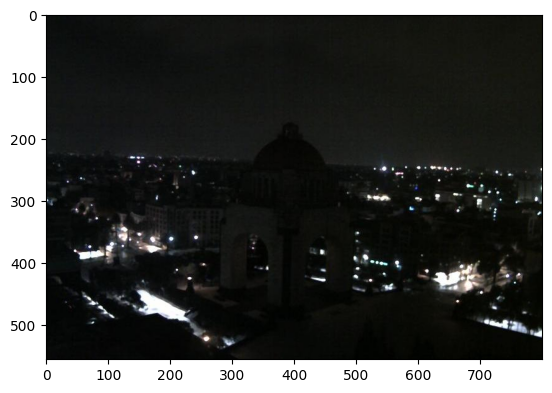

In [8]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

random_img_viz(train_img)
plt.show()

In [9]:
# Distribusi kelas pada data training
pd.Series([label for _, label in train_img]).value_counts()

day      120
night    120
Name: count, dtype: int64

Data training terdiri dari `240` gambar yang terbagi seimbang, yaitu `120` gambar `day` dan `120` gambar `night`. Ukuran gambar aslinya bervariasi, misalnya `(469, 640, 3)` sebanyak `41` gambar, `(700, 1280, 3)` sebanyak `33` gambar, dan `(458, 800, 3)` sebanyak `32` gambar. Karena ukurannya tidak seragam, gambar perlu distandarkan lebih dulu sebelum fitur diekstraksi.

## Langkah 3 - Pra Pengolahan Data

In [10]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

In [11]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0
    if(label == 'day'):
        num_val = 1

    return num_val

In [12]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [13]:
train_std_img_list = preprocess(train_img)

In [14]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 92
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 1  (1 = day, 0 = night)


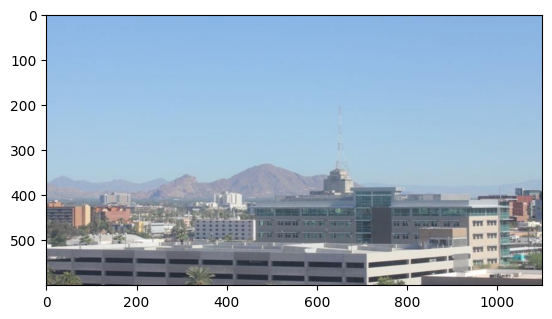

In [15]:
# Inspeksi visual pada gambar hasil pra pengolahan
idx = np.random.randint(0, len(train_std_img_list))
plt.imshow(train_std_img_list[idx][0])
print(f'Shape\t: {train_std_img_list[idx][0].shape}')
print(f'Label\t: {train_std_img_list[idx][1]}  (1 = day, 0 = night)')
plt.show()

Setelah pra pengolahan, seluruh gambar berukuran `(600, 1100, 3)` dan label sudah berupa angka (`1` untuk `day`, `0` untuk `night`). Karena fitur yang dipakai adalah rata-rata kecerahan per piksel, ukuran yang seragam membuat nilainya konsisten antar gambar.

## Langkah 4 - Ekstraksi Fitur

In [16]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:, :, 2])  # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 106
Avg Brighness: 135.2176


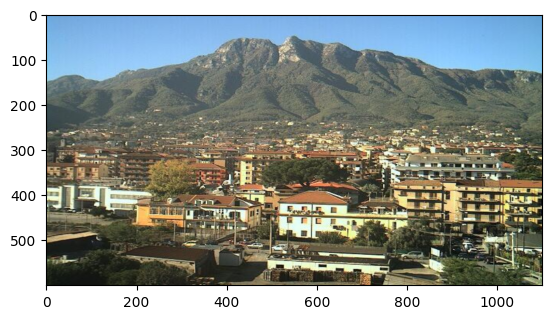

In [17]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

## Langkah 5 - Klasifikasi dengan Metode Threshold

In [18]:
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 71
Actual label: 1
Predicted label: 0


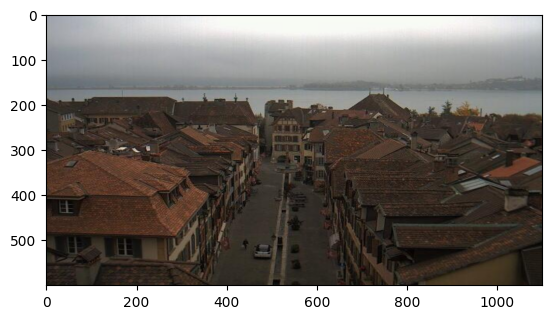

In [19]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

## Langkah 6 - Evaluasi Manual

In [20]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [21]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


Jobsheet menganjurkan untuk mengubah nilai ambang batas dan mengamati hasilnya. Fitur kecerahan dihitung sekali untuk semua gambar, lalu akurasinya dibandingkan pada rentang threshold 60 sampai 200.

Threshold terbaik pada data training: 100 (akurasi 0.9042)


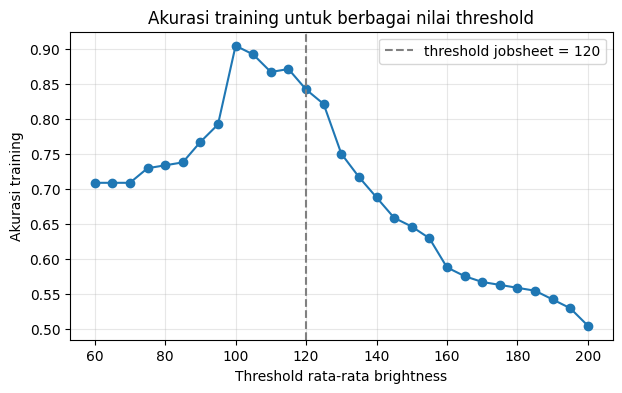

In [22]:
train_avg = np.array([avg_brightness(img) for img, _ in train_std_img_list])
train_lbl = np.array([lbl for _, lbl in train_std_img_list])

thresholds = np.arange(60, 201, 5)
acc_by_thr = [((train_avg > t).astype(int) == train_lbl).mean() for t in thresholds]

best_thr = thresholds[int(np.argmax(acc_by_thr))]
print(f'Threshold terbaik pada data training: {best_thr} (akurasi {max(acc_by_thr):.4f})')

plt.figure(figsize=(7, 4))
plt.plot(thresholds, acc_by_thr, marker='o')
plt.axvline(120, color='gray', linestyle='--', label='threshold jobsheet = 120')
plt.xlabel('Threshold rata-rata brightness')
plt.ylabel('Akurasi training')
plt.title('Akurasi training untuk berbagai nilai threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Dengan threshold `120` seperti pada jobsheet, akurasi pada data training adalah `0.8417`. Saat threshold diubah dari `60` sampai `200`, akurasi tertinggi pada data training dicapai di threshold `100` dengan `0.9042`, jadi nilai `120` ternyata belum yang terbaik. Puncaknya cukup tajam: akurasi turun ke sekitar `0.87` di threshold `110`, `0.84` di `120`, dan `0.75` di `130`. Pada sisi lain, di threshold `200` akurasinya tinggal sekitar `0.50` karena hampir semua gambar diprediksi sebagai malam. Artinya hasil metode ini sangat bergantung pada nilai threshold yang dipilih, dan nilai yang tepat harus dicari sendiri.

Selanjutnya evaluasi pada data testing. Data testing harus diperlakukan sama seperti data training (pra pengolahan dan ekstraksi fitur).

In [23]:
# Evaluate on test data
# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


Sebagai pembanding, threshold terbaik yang ditemukan dari data training (bukan dari data testing) juga dicoba pada data testing.

In [24]:
print(f'Threshold terbaik dari data training = {best_thr}')
evaluate(test_std_img_list, threshold=int(best_thr))

Threshold terbaik dari data training = 100
Accuracy: 0.9250


Pada data testing, threshold `120` menghasilkan akurasi `0.8688`, sedikit lebih tinggi dibanding akurasi training (`0.8417`). Selisih ini wajar karena threshold tidak dilatih dari data, sehingga tidak ada risiko overfitting; perbedaannya hanya soal data uji kebetulan sedikit lebih mudah untuk batas `120`. Threshold `100` yang dipilih dari data training ternyata juga memberi hasil lebih baik pada data testing (`0.925`), yang menandakan bahwa hasil penyetelan threshold pada data training bisa dipindahkan ke data baru.

## Klasifikasi dengan SVM

### Langkah 4 Alternatif - Membuat Feature Vectors

In [25]:
# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])  # Get the avg brightness from image
        img_label = img[1]                # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))

    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

In [26]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1.0
1,192.907867,1.0
2,132.133823,1.0
3,199.749191,1.0
4,109.947203,1.0


In [27]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1.0
1,157.826662,1.0
2,201.607444,1.0
3,191.237441,1.0
4,188.119652,1.0


Ringkasan nilai rata-rata kecerahan pada data training untuk masing-masing kelas (`0` = night, `1` = day).

In [28]:
train_avg_img.groupby('LABELS')['AVG_BRIGHT'].agg(['count', 'mean', 'min', 'max'])

,count,mean,min,max
LABELS,,,,
0.0,120,69.172472,8.113617,119.603174
1.0,120,137.330859,94.553459,200.020276


Tabel di atas menjelaskan kenapa threshold sekitar `100` bekerja paling baik. Rata-rata kecerahan gambar malam adalah sekitar `69` dan gambar siang sekitar `137`, jadi kedua kelas memang terpisah jauh secara rata-rata. Namun rentangnya saling tumpang tindih: gambar malam paling terang mencapai `119.6`, sedangkan gambar siang paling gelap hanya `94.6`. Pada rentang `94.6` sampai `119.6` itulah kesalahan klasifikasi tidak bisa dihindari oleh fitur kecerahan saja.

### Langkah 5 - Buat Model SVM

In [29]:
# import requied library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]

X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


### Langkah 6 - Evaluasi

In [30]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


In [31]:
from sklearn.metrics import confusion_matrix, classification_report

print(classification_report(y_test, y_test_pred, target_names=['night', 'day']))
pd.DataFrame(confusion_matrix(y_test, y_test_pred),
             index=['aktual night', 'aktual day'],
             columns=['prediksi night', 'prediksi day'])

              precision    recall  f1-score   support

       night       0.88      0.93      0.90        80
         day       0.92      0.88      0.90        80

    accuracy                           0.90       160
   macro avg       0.90      0.90      0.90       160
weighted avg       0.90      0.90      0.90       160



,prediksi night,prediksi day
aktual night,74,6
aktual day,10,70


Model SVM dengan kernel RBF bawaan mendapat akurasi `0.8583` pada data training dan `0.9` pada data testing, lebih baik dibanding threshold `120` yang hanya `0.8688` pada data testing. Dari confusion matrix, `74` dari `80` gambar malam dan `70` dari `80` gambar siang berhasil ditebak benar. Kesalahannya sedikit lebih banyak pada gambar siang yang diprediksi sebagai malam (`10` gambar) dibanding sebaliknya (`6` gambar). Hal ini sejalan dengan tabel statistik sebelumnya, yaitu ada gambar siang yang cukup gelap sehingga kecerahannya masuk ke rentang tumpang tindih dengan gambar malam. Nilai precision, recall, dan f1-score untuk kedua kelas sama-sama berada di sekitar `0.90`, jadi model tidak berat sebelah ke salah satu kelas.

Namun SVM ini tidak mengalahkan threshold yang sudah disetel dengan baik. Threshold `100` memberi `0.9042` pada data training dan `0.925` pada data testing, sedangkan SVM hanya `0.8583` dan `0.9`. Penyebabnya, SVM memakai pengaturan bawaan (`C=1`, `gamma='scale'`) yang teregulasi dan tidak berusaha menyesuaikan diri dengan setiap titik latih, sementara fitur yang dipakai hanya satu dimensi sehingga batas keputusan terbaiknya pun sebenarnya hanyalah sebuah threshold. Keunggulan SVM di sini adalah batas keputusan dicari otomatis dari data, bukan ditebak manual, dan hasilnya bisa diperbaiki lagi lewat tuning `C` dan `gamma` seperti pada Praktikum 4.

## Kesimpulan Praktikum 5

Dengan hanya satu fitur sederhana berupa rata-rata kecerahan (kanal V pada HSV), klasifikasi siang dan malam sudah mencapai akurasi `0.8688` dengan threshold `120` dan `0.90` dengan SVM pada data testing. Threshold yang disetel dari data training (`100`) bahkan memberi `0.925`, sehingga pada kasus satu fitur ini SVM bawaan tidak otomatis lebih unggul dari aturan threshold yang tepat. Keunggulan SVM baru benar-benar terasa kalau fitur ditambah, misalnya warna dominan atau distribusi kecerahan, karena rata-rata kecerahan saja tidak bisa membedakan gambar malam yang terang dari gambar siang yang gelap.